In [44]:
## -*- coding: utf-8 -*-
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from math import *
import matplotlib.cm as cm
import warnings
import pandas as pd
from pandas import DataFrame
from numba import njit, prange
import itertools
from scipy.stats import chi2
import scipy.stats as stats
from matplotlib import colors as mcolors
warnings.filterwarnings("ignore")

%matplotlib inline

In [45]:
### Define functions

'''
- make_fasta: creates a FASTA file from a list of sequences.
    - seqs: list of sequences to include in the FASTA file.
    - Name: name of the FASTA file to create (without extension).
    - key: type of sequences ('RNA' or 'DNA') to determine whether to replace 'T' with 'U'.

- permutation_test: performs a permutation test to compare the average values of two groups of elements in a matrix
    - matrix: input square matrix to analyze.
    - N: number of permutations to perform (default is 100000).
    - order: number of diagonals to consider as the "close" group (default is 1).
    - side: which tail to consider for the p-value calculation ('right' for greater than observed difference, 'left' for less than observed difference, default is 'right').
    - pos: which part of the matrix to consider ('upper' for upper triangle, 'lower' for lower triangle, default is 'lower').
    - allow_diag: whether to include the diagonal elements in the "close" group (default is False).

- mask_triangle: masks either the upper or lower triangle of a matrix with a specified value
    - matrix: input square matrix to mask.
    - upper: whether to mask the upper triangle (True) or lower triangle (False, default is True).
    - mask_number: value to use for masking the triangle (default is np.nan).

- round_labels: returns a list of labels corresponding to the given name
    - name: identifier for the set of labels to return (e.g., 'N14', 'N20', etc.).

- plotname: returns a formatted string for plotting based on the given name
    - name: identifier for the plot name to return (e.g., 'N14', 'N20', etc.).    
'''


def make_kmers(bases, k):
    return np.array([''.join(bp) for bp in itertools.product(bases, repeat = k)])

@njit(parallel=True)
def permutation_test(matrix, N=50000, order=1, side='right', pos='lower', allow_diag=False):
    if matrix.shape[0] != matrix.shape[1]:
        raise ValueError("Input matrix must be square")
    
    if order >= matrix.shape[0]:
        raise ValueError("order must be less than the size of the matrix")

    if pos == 'upper':
        matrix = matrix.T
    elif pos == 'lower':
        pass
    else:
        raise ValueError("pos must be 'upper' or 'lower'")
    
    if side not in ['right', 'left']:
        raise ValueError("side must be 'right' or 'left'")
    
    matrix = np.tril(matrix, k=-1) + np.tril(matrix).T
    R = matrix.shape[0]
    CR_counts = order * (2 * R - order - 1) / 2
    NCR_counts = (R - order) * (R - order - 1) / 2
    k = -1
    
    if allow_diag:
        CR_counts += R
        k = 0
    
    CR_counts = np.float64(CR_counts)
    NCR_counts = np.float64(NCR_counts)

    NCR_ave = np.tril(matrix, k=-(order+1)).sum() / NCR_counts
    CR_ave = (np.tril(matrix, k=k) - np.tril(matrix, k=-(order+1))).sum() / CR_counts
    obs_diff = NCR_ave - CR_ave

    count_r, count_l = 0, 0
    for n in prange(N):
        perm1 = np.random.permutation(R)
        perm2 = np.random.permutation(R)
        if  not allow_diag:
            perm1 = perm2
        perm_matrix = matrix[perm1][:, perm2]

        NCR_ave_perm = np.tril(perm_matrix, k=-(order+1)).sum() / NCR_counts
        CR_ave_perm = (np.tril(perm_matrix, k=k) - np.tril(perm_matrix, k=-(order+1))).sum() / CR_counts
        perm_diff = NCR_ave_perm - CR_ave_perm

        count_r += (perm_diff > obs_diff)
        count_l += (perm_diff < obs_diff)
    p_val_r = (count_r + 1) / (N + 1)
    p_val_l = (count_l + 1) / (N + 1)

    if side == 'right':
        return p_val_r
    elif side == 'left':
        return p_val_l

def mask_triangle(matrix, upper=True, mask_number=np.nan):
    masked_matrix = np.full_like(matrix, mask_number)
    for i in range(matrix.shape[0]):
        for j in range(i, matrix.shape[1]):
            if upper:
                masked_matrix[i][j] = matrix[i][j]
            else:
                masked_matrix[j][i] = matrix[j][i]
    return masked_matrix

def round_labels(name):
    if name in ['N14', 'N14_new', 'N14p_new']:
        return [1, 2, 3, 5, 6, 8, 10, 11, 13, 15, 17, 19, 20, 22, 24, 26, 28, 29, 30]
    elif name in ['N20', 'N20p']:
        return [2, 4, 6, 8, 11, 13, 15, 17, 19, 22, 24, 26, 28, 29]
    elif name == 'N14p':
        return [1, 2, 3, 5, 6, 8, 11, 13, 15, 17, 19, 22, 24, 26, 28, 29]
    elif name in ['single_N14', 'single_N14p']:
        return ['#1', '#2', '#3', '#4.1', '#4.2', '#4.3']
    else:
        raise ValueError('Invalid name')

def plotname(name):
    if name == 'N14':
        return '$\mathrm{N_{14}}$'
    elif name == 'N14_new':
        return '$\mathrm{N_{14}}$ new'
    elif name == 'N14p':
        return '$\mathrm{N_{14}>p}$'
    elif name == 'N14p_new':
        return '$\mathrm{N_{14}>p}$ new'
    elif name == 'N20':
        return '$\mathrm{N_{20}}$'
    elif name == 'N20p':
        return '$\mathrm{N_{20}>p}$'
    elif name == 'single_N14':
        return '$\mathrm{N_{14}}$ SR'
    elif name == 'single_N14p':
        return '$\mathrm{N_{14}>p}$ SR'
    else:
        return name

#### Response 1-3 & Fig S8A: Length distribution (single-round)

- key = 'N14', 'N14p', 'N20', 'N20p'

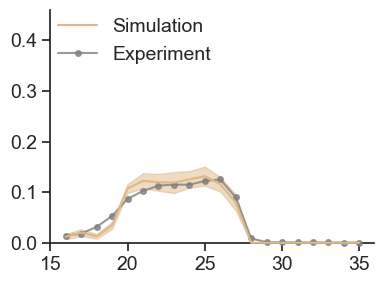

In [46]:
name = 'N14'

cols = ['burlywood', 'darkgoldenrod', 'skyblue', 'steelblue']

if name == 'N14':
    color = cols[0]
elif name == 'N14p':
    color = cols[1]
elif name == 'N20':
    color = cols[2]
else:
    color = cols[3]

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(4, 3))

result = np.load(f'data/processed/review/simulation_length_dist/{name}_results.npz', allow_pickle=True)
bins = result['bins']
freqs = result['freqs_sim']
freqs_exp = result['freqs_exp']
freqs_exp = freqs_exp[0] # for R1 or R2

mean_freq = freqs.mean(axis=0)
err_freq = freqs.std(axis=0) / np.sqrt(freqs.shape[0])
ax.plot(bins, mean_freq, color=color, lw=1.5, label='Simulation', zorder=10, clip_on=False)
ax.fill_between(bins, mean_freq - err_freq, mean_freq + err_freq, color=color, alpha=0.5)

ax.plot(bins, freqs_exp, color='gray', lw=1.5, marker='o', markersize=4, linestyle='-', alpha=0.8, label='Experiment', zorder=9, clip_on=False)

if name in ['N14', 'N14p']:
    ax.set_xticks(np.arange(15, 36, 5))
elif name in ['N20', 'N20p']:
    ax.set_xticks(np.arange(20, 46, 5))
# ax.set_xlabel('Length (nt)', fontsize=14)
# ax.set_ylabel('Frequency', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_ylim(0.0, 0.46)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=14, bbox_to_anchor=(0, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

#### Response 1-3 & Fig S8B: Length distribution (Transfer)


- key = 'N14', 'N14p', 'N20', 'N20p'
- Rounds = List, 1 ~ 30

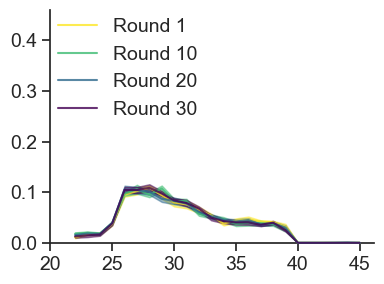

In [47]:
name = 'N20'
Rounds = [1, 10, 20, 30]

cols = plt.cm.get_cmap('viridis_r', 30)
result = np.load(f'data/processed/review/simulation_length_dist/{name}_transfer_results.npz', allow_pickle=True)
bins = result['bins']
freqs_set = result['freqs_set']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(4, 3))

for R in Rounds:
    freqs = freqs_set[R - 1]
    mean_freq = freqs.mean(axis=0)
    err_freq = freqs.std(axis=0) / np.sqrt(freqs.shape[0])
    ax.plot(bins, mean_freq, color=cols(R-1), lw=1.5, alpha=0.8, label=f'Round {R}', zorder=10, clip_on=False)
    ax.fill_between(bins, mean_freq - err_freq, mean_freq + err_freq, color=cols(R-1), alpha=0.5)

if name in ['N14', 'N14p']:
    ax.set_xticks(np.arange(15, 36, 5))
elif name in ['N20', 'N20p']:
    ax.set_xticks(np.arange(20, 46, 5))

# ax.set_xlabel('Length (nt)', fontsize=14)
# ax.set_ylabel('Frequency', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_ylim(0.0, 0.46)
# ax.set_xlim(21, 31)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=14, bbox_to_anchor=(0, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

#### Response 1-3 & Fig S8C: Length distribution (gamma variation)

- key = 'N14', 'N20'

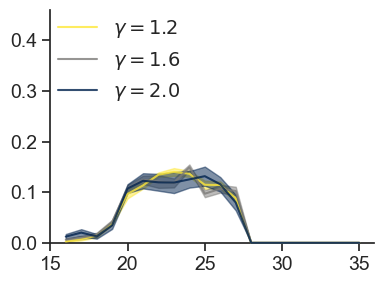

In [48]:
name = 'N14'
gammas = [1.2, 1.6, 2.0]

cols = plt.cm.get_cmap('cividis_r', 3)
result = np.load(f'data/processed/review/simulation_length_dist/{name}_gammas_results.npz', allow_pickle=True)
bins = result['bins']
freqs_set = result['freqs_set']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(4, 3))

for i, gamma in enumerate(gammas):
    freqs = freqs_set[i]
    mean_freq = freqs.mean(axis=0)
    err_freq = freqs.std(axis=0) / np.sqrt(freqs.shape[0])
    ax.plot(bins, mean_freq, color=cols(i), lw=1.5, alpha=0.8, label=f'$\\gamma = {gammas[i]}$', zorder=10, clip_on=False)
    ax.fill_between(bins, mean_freq - err_freq, mean_freq + err_freq, color=cols(i), alpha=0.5)

if name in ['N14', 'N14p']:
    ax.set_xticks(np.arange(15, 36, 5))
elif name in ['N20', 'N20p']:
    ax.set_xticks(np.arange(20, 46, 5))

# ax.set_xlabel('Length (nt)', fontsize=14)
# ax.set_ylabel('Frequency', fontsize=14)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_ylim(0.0, 0.46)
# ax.set_xlim(21, 31)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=14, bbox_to_anchor=(0, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()

#### Response 1-5, 2-3 & Fig S16: Additional complementarity analysis

- name = 'N14p
- length_key:
  - 'O18U22': 18–22 nt,
  - 'O23U30': 23-30 nt
- mfe_key:
  - 'O-5mfe': ∆G≧-5.0
  - 'U-5mfe': ∆G<-5.0
  - None: No threshold

In [49]:
name = 'N14p'
length_key = ('O18U22', 'O23U30')[1]
mfe_key = (None, 'O-5mfe', 'U-5mfe')[0]
k = 6

result = np.load(f'data/processed/review/ovlp/{name}_overlap_summary_sub{k}_{k}_k{k}_n10_unpairedTrue_terminalTrue_{length_key}_{mfe_key}.npz')
mat_nnz_set = result['mat_nnz']
Rs = result['Rs']
p_val = permutation_test(mat_nnz_set.mean(axis=0)[1:,1:], N=100000, order=1, side='left', pos='lower', allow_diag=True)
print(f'p-value: {p_val:.4f}')

p-value: 0.0565


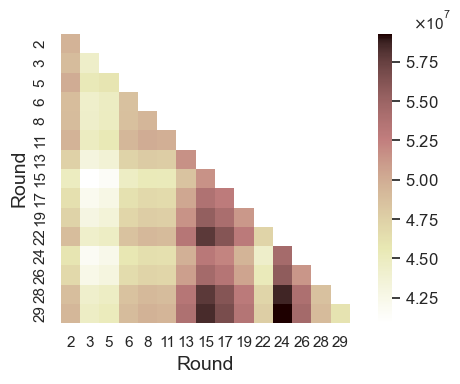

In [50]:
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6, 4))
cmap = sns.color_palette('pink_r', as_cmap=True)

if name == 'N20p':
    smat = np.mean(mat_nnz_set, axis=0)
    label = Rs
else:
    smat = np.mean(mat_nnz_set, axis=0)[1:, 1:]
    label = Rs[1:]

smat = mask_triangle(smat, upper=False)
sns.heatmap(smat, xticklabels=label, yticklabels=label, cmap=cmap, ax=ax, square=True, linewidths=0,
            vmin=None, vmax=None, annot=False, fmt=".2f", annot_kws={"size": 8})
cbar = ax.collections[0].colorbar
cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
cbar.ax.tick_params(labelsize=12)
cbar.ax.yaxis.offsetText.set_position((5.0,0))
cbar.ax.yaxis.offsetText.set_fontsize(11)
ax.tick_params(labelsize=11)
ax.set_xlabel('Round', size=14), ax.set_ylabel('Round', size=14)
plt.tight_layout()
plt.show()

18-22 nt: p-value = 0.0316*
18-22 nt
(ΔG ≥ -5.0 kcal/mol): p-value = 0.0459*
18-22 nt
(ΔG < -5.0 kcal/mol): p-value = 0.4437
23-30 nt: p-value = 0.0561


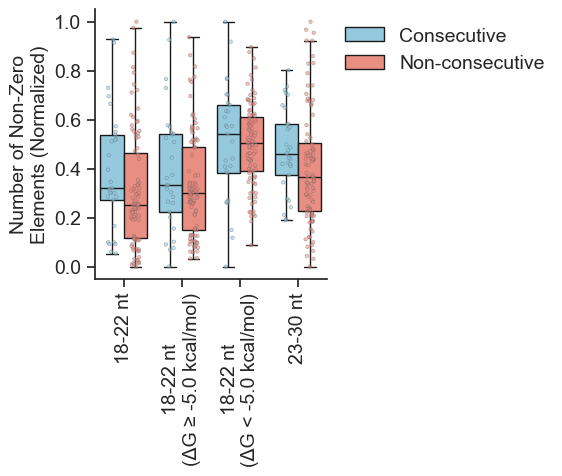

In [51]:
name = 'N14p'
k = 6
length_keys = ['O18U22', 'O18U22', 'O18U22', 'O23U30']
mfe_keys = [None, 'O-5mfe', 'U-5mfe', None]
names = ['18-22 nt', '18-22 nt\n(ΔG ≥ -5.0 kcal/mol)', '18-22 nt\n(ΔG < -5.0 kcal/mol)', '23-30 nt']

vals = []
labels = []
name_labels = []
for l in range(len(length_keys)):
    l_key = length_keys[l]
    m_key = mfe_keys[l]
    result = np.load(f'data/processed/review/ovlp/{name}_overlap_summary_sub{k}_{k}_k{k}_n10_unpairedTrue_terminalTrue_{l_key}_{m_key}.npz')
    mat_nnz = result['mat_nnz'].mean(axis=0)[1:, 1:]
    p_val = permutation_test(mat_nnz, N=100000, order=1, side='left', pos='lower', allow_diag=True)
    sign = '*' if p_val < 0.05 else ''
    print(f'{names[l]}: p-value = {p_val:.4f}{sign}')

    max_val = np.max(mat_nnz)
    min_val = np.min(mat_nnz)
    for i in range(mat_nnz.shape[0]):
        for j in range(i+1):
            if abs(i - j) <= 1:
                labels.append('Consecutive')
            else:
                labels.append('Non-consecutive')
            name_labels.append(names[l])
            vals.append((mat_nnz[i, j] - min_val) / (max_val - min_val) if max_val != min_val else 0)

df_plot = DataFrame({'Value': vals, 'Type': labels, 'Sample': name_labels})

order = ['18-22 nt', '18-22 nt\n(ΔG ≥ -5.0 kcal/mol)', '18-22 nt\n(ΔG < -5.0 kcal/mol)', '23-30 nt']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(3, 3.5))
sns.boxplot(data=df_plot, x='Sample', y='Value', hue='Type', order=order,
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, fliersize=3, showfliers=False, linecolor='k') #width=0.6
sns.stripplot(data=df_plot, x='Sample', y='Value', hue='Type', order=order,
            palette={'Consecutive': 'skyblue', 'Non-consecutive': 'salmon'},
            ax=ax, size = 2.5, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.15, dodge=True, legend=0)

ax.set_xticklabels(names, fontsize=16, rotation=90)
ax.set_xlabel(None)
ax.set_ylabel('Number of Non-Zero\nElements (Normalized)', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, title_fontsize=14, bbox_to_anchor=(1.0, 1.0), loc='upper left', frameon=False)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.show()

#### Response 1-5, 2-3 & Fig S18: Additional analysis for enrichment of sequence motifs
- semi_random: AGNN or CUNN
- key: whether to analyze the 3' and 5'end or the entire sequences

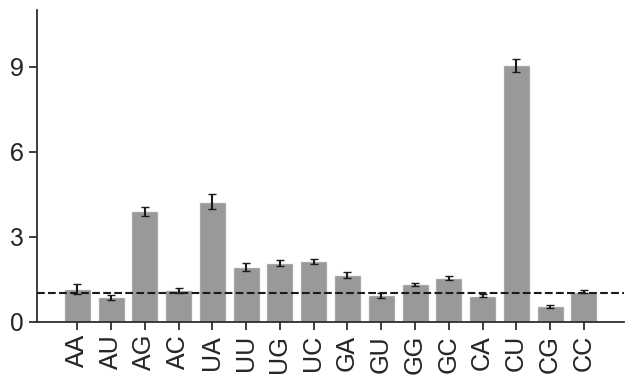

In [52]:
semi_random = 'AGNN' # or AGNN
key = 'termini' # or all

result = np.load(f'data/processed/review/kmer_freqs/kmer_freqs_{semi_random}_{key}.npz', allow_pickle=True)
kmer_freqs_set = result['kmer_freqs_set']
N = kmer_freqs_set.shape[0]

kmers = make_kmers(bases='AUGC', k=2)
mean = kmer_freqs_set.mean(axis=0)
std_err = kmer_freqs_set.std(axis=0, ddof=1)/np.sqrt(N)

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style="ticks", font='Arial')
fig, ax = plt.subplots(figsize=(6.5, 4))
plt.bar(kmers, mean, yerr=std_err, capsize=3, color='grey', linewidth=1, alpha=0.8)

ax.axhline(y=1.0, color='k', linestyle='--', linewidth=1.5, zorder=12)
ax.set_xticklabels(kmers, rotation=90, fontsize=20)
#ax.set_xlabel('XX', size=16)
#ax.set_ylabel('Relative frequency', size=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=18)
if semi_random == 'AGNN':
    ax.set_ylim(0,11)
    ax.set_yticks([0,3,6,9])
elif semi_random == 'CUNN':
    ax.set_ylim(0,14)
    ax.set_yticks([0,3,6,9,12])
plt.tight_layout()
plt.show()

#### Response 2-4 & Fig S13: Variation in terminal 3-mer frequencies
- name: N14 or N14p


In [53]:
import scipy.stats as stats

name = 'N14'
k = 3

result = np.load(f'data/processed/review/kmer_freqs_std/{name}_k{k}_kmer_freqs.npz', allow_pickle=True)
data_5_set = result['data_5_set']
data_3_set = result['data_3_set']
data_single_5_set = result['data_single_5_set']
data_single_3_set = result['data_single_3_set']
kmers_5 = result['kmers_5']
kmers_3 = result['kmers_3']
Rs = result['Rs']
Rs_single = result['Rs_single']

data_5 = np.mean(data_5_set, axis=0)
data_3 = np.mean(data_3_set, axis=0)
data_single_5 = np.mean(data_single_5_set, axis=0)
data_single_3 = np.mean(data_single_3_set, axis=0)

data_5 = DataFrame(data_5, columns=kmers_5, index=Rs)
data_3 = DataFrame(data_3, columns=kmers_3, index=Rs)
data_single_5 = DataFrame(data_single_5, columns=kmers_5, index=Rs_single)
data_single_3 = DataFrame(data_single_3, columns=kmers_3, index=Rs_single)

std_5 = data_5.std(axis=0, ddof=1)
std_3 = data_3.std(axis=0, ddof=1)
std_single_5 = data_single_5.std(axis=0, ddof=1)
std_single_3 = data_single_3.std(axis=0, ddof=1)
labels = ['5\'-end'] * len(kmers_5) + ['3\'-end'] * len(kmers_3) + ['5\'-end'] * len(kmers_5) + ['3\'-end'] * len(kmers_3)
types = ['Transfer'] * (len(kmers_5) + len(kmers_3)) + ['Single'] * (len(kmers_5) + len(kmers_3))
data = DataFrame({'std': np.concatenate([std_5.values, std_3.values, std_single_5.values, std_single_3.values]), 'label': labels, 'type': types})

_, p_value_5 = stats.ttest_ind(std_5, std_single_5, alternative='greater', equal_var=False) #one-sided Welch’s t-test.
_, p_value_3 = stats.ttest_ind(std_3, std_single_3, alternative='greater', equal_var=False) #one-sided Welch’s t-test.
# _, p_value_5 = stats.ttest_ind(std_5, std_single_5, alternative='two-sided', equal_var=False) #two-sided Welch’s t-test.
# _, p_value_3 = stats.ttest_ind(std_3, std_single_3, alternative='two-sided', equal_var=False) #two-sided Welch’s t-test.

_, p_value_3_paired = stats.ttest_rel(std_3, std_single_3, alternative='two-sided')

print(f'P-value for 5\' end: {p_value_5:.4e}')
print(f'P-value for 3\' end: {p_value_3:.4e}')
print(f'P-value for 3_paired\' end: {p_value_3_paired:.4e}')

data.groupby(['label', 'type'])['std'].agg(['min', 'max'])

P-value for 5' end: 1.1210e-03
P-value for 3' end: 2.6568e-06
P-value for 3_paired' end: 2.1648e-09


min       max
label  type                        
3'-end Single    0.000137  0.001002
       Transfer  0.000203  0.002280
5'-end Single    0.000064  0.002129
       Transfer  0.000182  0.003423

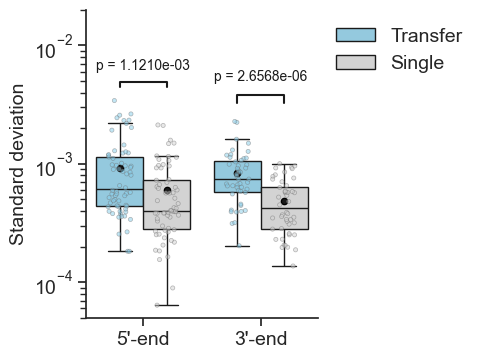

In [54]:
plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
fig, ax = plt.subplots(figsize=(3, 4))

colors = ['skyblue', 'lightgray']

sns.boxplot(data=data, x='label', y='std', hue='type', palette=colors, ax=ax, fliersize=3, showfliers=False, linecolor='k',\
           showmeans=True, meanprops={'marker': 'o', 'markerfacecolor': 'k', 'markeredgecolor': 'black', 'markersize': 4.5, 'markeredgewidth': 1})
sns.stripplot(data=data, x='label', y='std', hue='type', palette=colors, ax=ax, size=3, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.2, dodge=True, legend=0)


for i, (std_group, std_single_group) in enumerate(zip([std_5, std_3], [std_single_5, std_single_3])):
    x1, x2 = i - 0.2, i + 0.2
    y, h, col = max(std_group.max(), std_single_group.max()) + 0.001, 0.0005, 'k'
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c=col)
    p_value = p_value_5 if i == 0 else p_value_3
    ax.text((x1+x2)*.5, y+h+0.001, f"p = {p_value:.4e}", ha='center', va='bottom', color=col, fontsize=10)

ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylim(0.00005, 0.02)
ax.set_ylabel('Standard deviation', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=14, title_fontsize=14, bbox_to_anchor=(1.0, 1.0), loc='upper left', frameon=False)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.show()


#### Response 2-7i & Fig S17C: Length distribution of semi-random + N14p products
- min_len: minimum length
- max_len: maximum length

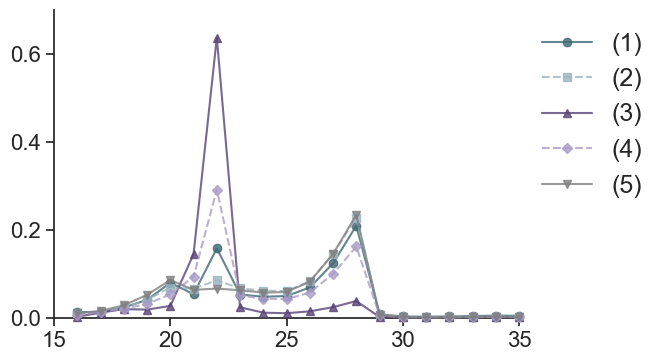

In [55]:
min_len, max_len = 16, 35

result = np.load('data/processed/review/semi-random_length_dist/2mer-no-filter_length_distribution.npz')
length_range = result['length_range']
freqs_set = result['freqs_set']

plt.rcParams['font.family'] = 'Arial'
sns.set_theme(style='ticks', font='Arial')
#fig, ax = plt.subplots(figsize=(4, 3))
fig, ax = plt.subplots(figsize=(6, 4))

#colors = ['firebrick', 'salmon', 'royalblue', 'skyblue', 'gray']
#colors = ['#5C6F76', '#849EA8', '#514E68', '#747095', 'darkgrey']
colors = ['#3F6873', '#9CB5BE', '#574477', '#AA9CC7', 'grey']
markers = ['o', 's', '^', 'D', 'v']
markersizes = [6,6,6,5,6]
linestyles = ['-', '--', '-', '--', '-']

#labels = ['$\mathrm{AG(NNAG)_{5}}$ 0.8 µM', '$\mathrm{AG(NNAG)_{5}}$ 0.08 µM', '$\mathrm{CU(NNCU)_{5}}$ 2.0 µM', '$\mathrm{CU(NNCU)_{5}}$ 0.2 µM', 'Negative control']
labels = ['(1)', '(2)', '(3)', '(4)', '(5)']
for i in range(5):
    freqs = freqs_set[i]
    freqs = freqs[min_len - length_range[0]:max_len - length_range[0] + 1]
    ax.plot(range(min_len, max_len + 1), freqs, marker=markers[i], label=labels[i], linestyle=linestyles[i],
            color=colors[i], markersize=markersizes[i], linewidth=1.5, alpha=0.8, clip_on=False, zorder=10)

# ax.set_xlabel('Length (nt)', fontsize=14)
# ax.set_ylabel('Frequency', fontsize=14)
#ax.set_xlim(min_len - 0.5, max_len + 0.5)
# ax.set_yscale('log')
ax.set_ylim(0,0.7)
ax.set_xlim(15,35)
ax.legend(fontsize=18, frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
ax.tick_params(axis='both', which='major', labelsize=16)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# plt.tight_layout()
plt.show()

#### Response 2-7d & Fig S2B: Probability of sequence removal during homology searches
- key = 'PR_1st' or 'PR_2nd'

In [56]:
df = pd.read_csv('data/processed/review/sequence_depth/260722_sequence_depth.csv')
df = df[:63]

labels = np.array([name.split('_')[0] for name in df['sample'].values])
PR_1st = (df['abs_matching'].values - df['1st_blast'].values) / df['abs_matching'].values# * 100
PR_2nd = (df['1st_blast'].values - df['2nd_blast'].values) / df['1st_blast'].values# * 100

df_plot = pd.DataFrame({
    'Sample': labels,
    'PR_1st': PR_1st,
    'PR_2nd': PR_2nd
})

df = pd.read_csv('data/processed/review/sequence_depth/260731_FP.csv')
df_exp = df[:4]
FPR = {'PR_1st': (1e6 + 1 - df_exp['1st_blast'].values) / 1e4, 'PR_2nd': (1e6 + 1 - df_exp['2nd_blast'].values) / 1e4}
df_rand = df[4:]
FPR_rand = {'PR_1st': (1e6 + 1 - df_rand['1st_blast'].values) / 1e4, 'PR_2nd': (1e6 + 1 - df_rand['2nd_blast'].values) / 1e4}

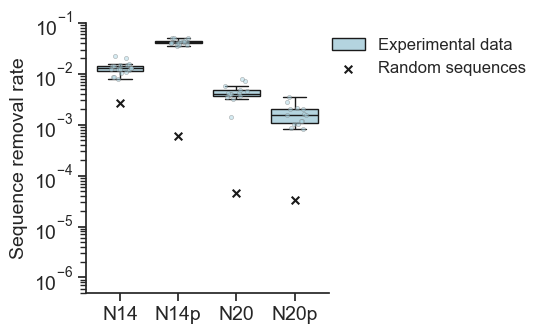

In [57]:
key = 'PR_1st' # or 'PR_2nd'

sns.set_theme(style='ticks')
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(5.5, 3.5))
sns.boxplot(data=df_plot, x='Sample', y=key, color='lightblue', ax=ax, fliersize=3, showfliers=False, linecolor='k', label='Experimental data', zorder=5)
sns.stripplot(data=df_plot, x='Sample', y=key, color='lightblue', ax=ax, size=3, alpha=0.5, linewidth=0.5, zorder=10, jitter=0.2, dodge=True, legend=0)
# ax.scatter(np.arange(4), FPR[key], color='blue', s=30, marker='x', label='Experimental data', zorder=20)
ax.scatter(np.arange(4), FPR_rand[key]/100, color='k', s=30, marker='x', label='Random sequences', zorder=20)

ax.set_xlabel(None, fontsize=14)
ax.set_ylabel('Sequence removal rate', fontsize=14) #%ではない
ax.tick_params(axis='both', which='major', labelsize=14)
ax.set_yscale('log')
ax.set_ylim(0.0000005, 0.1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=12, frameon=False, loc='upper left', bbox_to_anchor=(0.95, 1))
plt.tight_layout()
plt.show()